# DAY6 실습 01 — 단순회귀 : 회귀식과 결정계수

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "ai4i2020.csv")

df = pd.read_csv(csv_path)

data = df.copy()

Mounted at /content/drive


## 데이터와 질문

| 데이터 파일 | 출처 | 한 행 | 쓰는 곳 |
|---|---|---|---|
| `ai4i2020.csv` | UCI Machine Learning Repository - [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset) | 운전 기록 1건 (10,000건) |
| `auto_mpg.csv` | UCI Machine Learning Repository - [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) (CC BY 4.0) | 자동차 1대 (398대) |  

| AI4I 바꾼 이름 | 뜻 | 단위 |
|---|---|---|
| `air_temperature_k` | 공기온도 | K (켈빈) |
| `process_temperature_k` | 공정온도 | K |

| 자동차 열 이름 | 뜻 | 단위 |
|---|---|---|
| `mpg` | 연비. 클수록 연료를 덜 쓴다 | 마일/갤런 |
| `weight` | 무게 | 파운드 |
| `acceleration` | 가속시간 : 시속 0 → 60마일에 걸리는 시간. 클수록 느린 차 | 초 |
| `cylinders` | 실린더(기통) 수 | 개 |
| `origin` | 생산지역 (usa · europe · japan) | 없음 |

**질문** : 공기온도가 1 K 높은 기록에서 공정온도는 얼마나 높다고 예측할 수 있는가? 그 직선은 공정온도를 얼마나 설명하는가?

**실습 전제** : 두 자료 모두 관찰자료다. 회귀식은 "함께 움직이는 정도"를 식으로 나타낸 것이고, 한쪽을 바꾸면 다른 쪽이 바뀐다는 인과를 뜻하지 않는다.

In [ ]:
raw = data.rename(columns={"Air temperature [K]": "air_temperature_k",       # 공기온도 (K)
                           "Process temperature [K]": "process_temperature_k",  # 공정온도 (K)
                           "Rotational speed [rpm]": "rotational_speed_rpm",    # 회전수 (rpm)
                           "Torque [Nm]": "torque_nm",                          # 토크 (Nm)
                           "Tool wear [min]": "tool_wear_min"})                 # 공구 마모시간 (분)

numeric_cols = ["air_temperature_k", "process_temperature_k", "rotational_speed_rpm", "torque_nm", "tool_wear_min"]
print("행·열:", raw.shape)
print(raw[numeric_cols].isna().sum())        # 열마다 결측(빈 값) 개수. 상관은 같은 행의 두 값으로 계산하므로 먼저 확인한다

행·열: (10000, 14)
air_temperature_k        0
process_temperature_k    0
rotational_speed_rpm     0
torque_nm                0
tool_wear_min            0
dtype: int64


In [ ]:
# 자동차 자료도 같은 폴더에서 읽는다
cars = pd.read_csv(os.path.join(data_folder, "auto_mpg.csv"))
#   os.path.join : 폴더 경로와 파일 이름을 이어 붙여 전체 경로를 만든다
print("자동차 행·열:", cars.shape)

자동차 행·열: (398, 9)


## 1. 회귀분석이란

**상관분석**은 두 변수가 함께 움직이는 정도를 숫자 하나(r)로 나타낸다. "공기온도가 1 K 높으면 공정온도는 **몇 K** 높은가?", "공기온도가 300 K일 때 공정온도는 **얼마**인가?"처럼 구체적인 값을 묻는 질문에는 회귀분석으로 답한다.

**회귀분석**은 독립변수 X가 달라질 때 종속변수 Y의 예측값이 얼마나 달라지는지를 식으로 나타내는 분석이다. X가 하나이고 관계를 직선으로 나타내면 **단순선형회귀**라고 한다.



| 기호 | 읽기 | 뜻 |
|---|---|---|
| x | 엑스 | **독립변수** : 설명에 쓰는 변수 (예 : 공기온도) |
| y | 와이 | **종속변수** : 설명하거나 예측하려는 변수 (예 : 공정온도) |
| ŷ | 와이 햇 | 회귀식이 계산한 y의 **예측값** |
| b₁ | 비 원 | **기울기** : x가 1 늘 때 예측값의 변화 |
| b₀ | 비 제로 | **절편** : x가 0일 때의 예측값 |

공식 문서 : [NIST e-Handbook : Linear Least Squares Regression](https://www.itl.nist.gov/div898/handbook/pmd/section1/pmd141.htm)

## 2. 회귀식 구하기

**회귀식**은 산점도의 점들 사이를 지나는 직선을 식으로 나타낸 것이다. 회귀식이 있으면 관계를 숫자로 말하고, 새 x 값의 예측값을 계산할 수 있다.

| 함수 | 기능 |
|---|---|
| `stats.linregress(x, y)` | 단순선형회귀. x에 독립변수, y에 종속변수를 넣는다. 순서를 바꾸면 다른 식이 나온다 |
| `결과.slope` | 기울기 b₁ |
| `결과.intercept` | 절편 b₀ |

공식 문서 : [scipy.stats.linregress](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html)

In [ ]:
# [예제] 공기온도(x)로 공정온도(y)를 예측하는 회귀식을 구한다
temp_pair = raw[["air_temperature_k", "process_temperature_k"]].dropna()   # 두 열을 함께 뽑아 같은 행의 짝을 유지한다
x = temp_pair["air_temperature_k"]          # 독립변수 : 공기온도
y = temp_pair["process_temperature_k"]      # 종속변수 : 공정온도

temp_reg = stats.linregress(x, y)
#   linregress(x, y) : x 독립변수, y 종속변수, 결과를 temp_reg 에 담아 두고 필요한 값을 꺼내 쓴다
print("기울기 b₁:", round(temp_reg.slope, 4))
print("절편 b₀:", round(temp_reg.intercept, 3))
print("회귀식 : 공정온도 예측값 =", round(temp_reg.intercept, 3), "+", round(temp_reg.slope, 4), "× 공기온도")
print("관측 범위 : 공기온도", x.min(), "~", x.max(), "K")

# [결과]
# - 회귀식 : 공정온도 예측값 = 115.041 + 0.6499 × 공기온도
# - 기울기 0.6499 : 공기온도가 1 K 높은 기록에서 공정온도 예측값이 약 0.65 K 높다 (단위 : K ÷ K)
# - 절편 115.041 : 공기온도가 0 K 일 때의 계산값이다. 0 K 는 관측 범위(295.3 ~ 304.5 K) 밖이라 해석하지 않고, 직선을 그리는 데만 쓴다

기울기 b₁: 0.6499
절편 b₀: 115.041
회귀식 : 공정온도 예측값 = 115.041 + 0.6499 × 공기온도
관측 범위 : 공기온도 295.3 ~ 304.5 K


## 3. 예측값과 잔차

회귀식은 점들을 정확히 지나지 않는다. 직선이 각 관측을 얼마나 맞히고 얼마나 놓쳤는지는 예측값과 잔차로 나타낸다.

| 용어 | 정의 | 식 |
|---|---|---|
| **예측값** | 회귀식에 x를 넣어 계산한 y 값 | ŷ = b₀ + b₁x |
| **잔차** | 실제값과 예측값의 차이. 직선이 설명하지 못하고 남은 부분 | e = y − ŷ |

- 잔차가 양수면 실제값이 직선보다 위, 음수면 아래에 있다
- 잔차가 크다는 것은 예측값과 실제값의 차이가 크다는 뜻이지, 측정값이 잘못되었다는것은 아니다.예를들어 공정온도는 공기온도 외에도 여러 요인의 영향을 받기 때문에 회귀선으로 설명되지 않는 부분이 남을 수 있다.

| 함수 | 기능 |
|---|---|
| `plt.plot(x, y, color="red")` | 점들을 선으로 잇는다. 회귀선을 그릴 때 쓴다 |
| `시리즈.sort_values()` | 값을 작은 순서로 정렬한다. 선을 왼쪽에서 오른쪽으로 그리기 위해 쓴다 |

공식 문서 : [matplotlib.pyplot.plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html)

,공기온도,실제 공정온도,예측 공정온도,잔차
0,298.1,308.6,308.77,-0.17
1,298.2,308.7,308.83,-0.13
2,298.1,308.5,308.77,-0.27
3,298.2,308.6,308.83,-0.23
4,298.2,308.7,308.83,-0.13


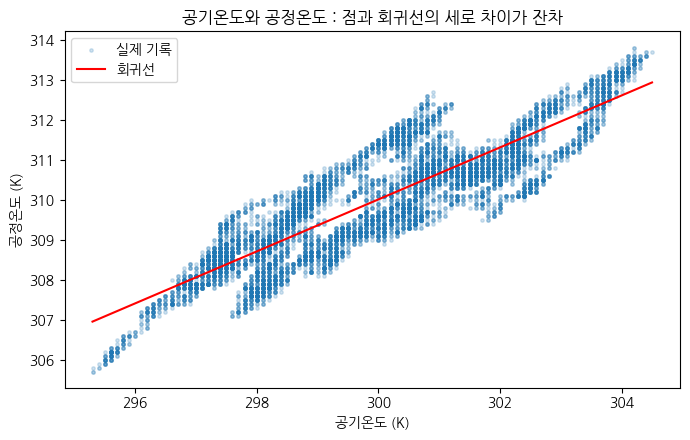

잔차 평균: 0.0 / 잔차 표준편차: 0.72 K


In [ ]:
# [예제] 기록마다 예측값과 잔차를 구하고, 회귀선을 산점도 위에 그린다
temp_pred = temp_reg.intercept + temp_reg.slope * x      # 예측값 ŷ : 기록마다 계산된다
temp_resid = y - temp_pred                                # 잔차 e = 실제값 − 예측값

table = pd.DataFrame({"공기온도": x, "실제 공정온도": y, "예측 공정온도": temp_pred, "잔차": temp_resid})
display(table.head().round(2))

line_x = x.sort_values()                                  # 선을 왼쪽부터 그리려고 x 를 정렬한다
line_y = temp_reg.intercept + temp_reg.slope * line_x
plt.figure(figsize=(7, 4.5))
plt.scatter(x, y, s=6, alpha=0.2, label="실제 기록")
plt.plot(line_x, line_y, color="red", label="회귀선")
plt.xlabel("공기온도 (K)")
plt.ylabel("공정온도 (K)")
plt.title("공기온도와 공정온도 : 점과 회귀선의 세로 차이가 잔차")
plt.legend()                                              # legend : label 로 붙인 이름표를 보여 준다
plt.tight_layout()
plt.show()

print("잔차 평균:", round(temp_resid.mean(), 4), "/ 잔차 표준편차:", round(temp_resid.std(), 2), "K")

# [결과]
# - 첫 기록은 실제 308.6 K, 예측 308.77 K 라 잔차가 −0.17 K 다 (실제값이 직선보다 조금 아래)
# - 회귀선은 점들의 띠 가운데를 지나간다. 잔차 평균은 0 이고(최소제곱 직선의 성질), 잔차 표준편차는 약 0.72 K 다
# - 공정온도 예측값이 실제와 보통 0.7 K 안팎 차이 난다는 뜻이다

## 4. 최소제곱법 : 가장 잘 맞는 직선의 기준
산점도의 점들 사이에는 여러 직선을 그을 수 있다. 이 중 데이터에 가장 잘 맞는 직선을 선택하려면 기준이 필요하다.
  
  최소제곱법(Ordinary Least Squares, OLS)은 각 관측값과 회귀선의 예측값 사이의 차이인 잔차를 제곱하여 모두 더한 값(잔차제곱합, SSE)이 가장 작아지도록 회귀선을 구하는 방법이다.

잔차를 제곱하면 양수와 음수가 서로 상쇄되지 않고, 큰 잔차에는 더 큰 가중치가 주어진다.


| 값 | 공식 | 뜻 |
|---|---|---|
| 기울기 b₁ | x와 y의 공분산 ÷ x의 분산 | x가 혼자 퍼진 정도에 비해 y와 함께 움직인 정도 |
| 절편 b₀ | y의 평균 − b₁ × x의 평균 | 회귀선은 항상 (x 평균, y 평균)을 지난다 |

공식 문서 : [NIST e-Handbook : Least Squares](https://www.itl.nist.gov/div898/handbook/pmd/section1/pmd141.htm)

In [ ]:
# [예제] 기울기가 다른 후보 직선 세 개의 잔차제곱합을 비교하고, 공식으로 기울기를 다시 구한다
for b1 in [0.40, 0.65, 0.90]:                             # 후보 기울기를 하나씩 넣어 아래 줄을 반복한다
    b0 = y.mean() - b1 * x.mean()                         # 세 직선 모두 (x 평균, y 평균)을 지나게 절편을 맞춘다
    sse = ((y - (b0 + b1 * x)) ** 2).sum()                # 잔차제곱합 : 잔차를 제곱해 모두 더한다. ** 2 는 제곱
    print("기울기", b1, "-- 잔차제곱합", round(sse, 1))

# 공분산과 분산을 이용한 기울기 계산
print("기울기 공식 :공분산 ÷ X의 분산 =", round(x.cov(y), 3), "÷", round(x.var(), 3), "=", round(x.cov(y) / x.var(), 4))
#   x.cov(y) : 공분산, x.var() : 분산 (둘 다 n − 1 로 나눈다)

print("linregress 기울기 :", round(temp_reg.slope, 4))

# [결과]
# - 잔차제곱합 : 기울기 0.40 → 7,614.3 / 0.65 → 5,116.5 / 0.90 → 7,619.5. 기울기 0.65 직선이 가장 작다
# - 공분산 2.600 ÷ 분산 4.001 = 0.6499 로 linregress 기울기와 같다 → linregress 는 최소제곱 직선을 구한 것이다

기울기 0.4 -- 잔차제곱합 7614.3
기울기 0.65 -- 잔차제곱합 5116.5
기울기 0.9 -- 잔차제곱합 7619.5
기울기 공식 :공분산 ÷ X의 분산 = 2.6 ÷ 4.001 = 0.6499
linregress 기울기 : 0.6499


## 5. 결정계수 R² : 회귀식의 설명력

회귀식을 구했어도, 그 직선이 y의 변화를 얼마나 설명하는지는 따로 확인해야 한다.

**결정계수** R²는 y의 전체 변동 중 회귀식이 설명한 비율이다. 0 ~ 1 사이이고, 1에 가까울수록 점들이 직선 가까이 모여 있다.

| 이름 | 식 | 뜻 |
|---|---|---|
| 전체 제곱합 (SST) | Σ(y − ȳ)² | y가 평균에서 흩어진 전체 크기 |
| 잔차 제곱합 (SSE) | Σ(y − ŷ)² | 직선이 설명하지 못한 크기 |
| 결정계수 | R² = 1 − SSE ÷ SST | 전체 중 직선이 설명한 비율 |

단순회귀에서는 **R² = r²** (상관계수의 제곱)이다. `linregress` 결과의 `rvalue`가 r이다.

- R²는 방향을 알려 주지 않는다. 방향은 기울기의 부호로 본다
- R²가 높다고 인과가 증명되거나 새 자료에서도 같은 정확도가 보장되지는 않는다

공식 문서 : [scipy.stats.linregress](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html)

In [ ]:
# [예제] R² 를 정의대로 계산하고, r² 와 같은지 확인한다
sst = ((y - y.mean()) ** 2).sum()           # 전체 제곱합
sse = (temp_resid ** 2).sum()               # 잔차 제곱합
print("SST:", round(sst, 1), "/ SSE:", round(sse, 1))
print("R² = 1 − SSE ÷ SST =", round(1 - sse / sst, 4))
print("r² =", round(temp_reg.rvalue, 4), "의 제곱 =", round(temp_reg.rvalue ** 2, 4))

# [결과]
# - R² = 0.7676 이다. 공정온도 변동의 약 77% 를 공기온도의 직선으로 설명한다
# - r = 0.8761 의 제곱과 같다 (단순회귀에서는 R² = r²)
# - 나머지 약 23% 는 이 회귀식이 설명하지 못한 변동이다 (다른 요인 · 측정 오차 등)

SST: 22012.5 / SSE: 5116.5
R² = 1 − SSE ÷ SST = 0.7676
r² = 0.8761 의 제곱 = 0.7676


## 6. 문제 : 일본 차의 가속시간으로 연비 예측하기

일본 차 79대의 가속시간과 연비는 피어슨 r = 0.401로 보통 정도의 양의 상관이다. 회귀식을 구하면 "가속시간이 1초 긴 차의 연비 예측값이 몇 mpg 높은가"로 답할 수 있다.

In [ ]:
# 문제 1) 회귀식
# 일본 차(origin 이 japan)만 골라 가속시간(x)으로 연비(y)를 예측하는 회귀식을 구하고, 기울기를 단위와 함께 해석하시오.



In [ ]:
# 문제 2) 예측값
# 가속시간이 15초인 일본 차의 연비 예측값을 구하고, 15초가 관측 범위 안인지 확인하시오.



In [ ]:
# 문제 3) 결정계수
# 결정계수 R² 를 구하고, 회귀선과 함께 산점도를 그린 뒤 이 회귀식의 설명력을 해석하시오.



## 7. 정리 : 회귀식과 결정계수

| 순서 | 할 일 | 목적 | 코드 |
|---|---|---|---|
| 1) | x(설명에 쓰는 변수)와 y(예측할 변수)를 정한다 | 회귀는 역할에 따라 식이 달라진다 | `x = 표["열"]`, `y = 표["열"]` |
| 2) | 회귀식을 구한다 | 관계를 숫자로 말하고 예측값을 계산한다 | `res = stats.linregress(x, y)` → `res.slope`, `res.intercept` |
| 3) | 예측값과 잔차를 구한다 | 직선이 맞힌 부분과 놓친 부분을 본다 | `pred = res.intercept + res.slope * x`, `resid = y - pred` |
| 4) | 결정계수를 구한다 | 직선이 y를 얼마나 설명하는지 본다 | `res.rvalue ** 2` |

